# Introduction

In this notebook we test performance of ABC on basic linear regression problem.

We explore all possible method configurations.

# 1) Generate data

In [19]:
from pygom.model.transition import Transition
from pygom.model.pygom_model import Model

import matplotlib.pyplot as plt
import numpy as np

transitions = [
    Transition('S', 'I', rate='beta * S * I / N'),
    Transition('I', 'R', rate='gamma * I')
]

states = [
    'S',
    'I',
    'R'
]

params = [
    'beta',
    'gamma'
]

derived_params =[
    ('N', 'S + I + R')
]

mod = Model(state=states, param=params, derived_param=derived_params, event=transitions)

t_eval = np.arange(0, 200, 7)

mod.parameters = {
    'beta': 0.3,
    'gamma': 0.25
}

i0 = 10
N = 10_000

mod.initial_states = {
    'S': N-i0,
    'I': i0,
    'R': 0
}

out = mod.solve_stochastic(
    t=t_eval,
    method="fixed_tau",
    seed=0,
    tau=0.1
)

# out = mod.solve_deterministic(
#     t=t_eval
# )

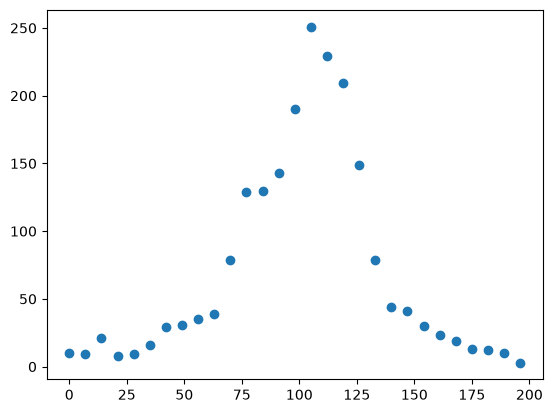

In [20]:
t_dat = out[0].result.t
I_dat = out[0].result.y[:, 1]

# Plot
plt.scatter(t_dat, I_dat)
plt.show()

# Model

In [21]:
states = ['S', 'I', 'R']
params = ['beta', 'gamma']
derived_params =[ ('N', 'S + I + R') ]

transitions = [
    Transition('S', 'I', rate='beta * S * I / N'),
    Transition('I', 'R', rate='gamma * I')
]

mod = Model(state=states, param=params, derived_param=derived_params, event=transitions)

# Simulator

In [22]:
from pygom.inference.fitting_problem_spec import DeterministicSimulator

simulator = DeterministicSimulator(times = t_dat)

# Observable

In [23]:
from pygom.inference.fitting_problem_spec import Observable

class Infections(Observable):
    name = "infections"

    def evaluate(self, simulation_output):
        inf_sim = simulation_output.y[:, 1]
        return inf_sim

# Target

In [24]:
from pygom.inference.fitting_problem_spec import Target
from pygom.inference.error_models import AbsoluteSquaredError

spectral_overlap = Target(
    observable=Infections(),
    error_model=AbsoluteSquaredError(),
    value=I_dat
)

targets = [spectral_overlap]

# Unknowns

In [25]:
from pygom.inference.fitting_problem_spec import Unknown, UnknownSpec
from pygom.inference.priors import UniformPrior

beta = Unknown(
    id='beta',
    prior=UniformPrior(0.1, 0.5),
    lower=0,
    upper=1
)

gamma = Unknown(
    id='gamma',
    prior=UniformPrior(0.1, 0.4),
    lower=0,
    upper=1
)

I0 = Unknown(
    id='I',
    prior=UniformPrior(1, 50),
    lower=1,
    upper=100
)

unknowns = UnknownSpec(
    parameters=[beta, gamma],
    initial_conditions=[I0]
)

# Fixed

In [26]:
from pygom.inference.fitting_problem_spec import FixedSpec

fixed =  FixedSpec(
    initial_conditions ={'S': 10_000, 'R': 0}
)

# Constraints

In [27]:
from pygom.inference.fitting_problem_spec import Resolver, ResolverVariables, ModelVariables

class FixedPop(Resolver):

    inputs = ResolverVariables(
        initial_conditions={"I", "R"}
    )

    outputs = ResolverVariables(
        initial_conditions={"S"}
    )

    def resolve(self, params, initial_conditions):

        I = initial_conditions["I"]

        N = 10_000

        S = N - I

        return ModelVariables(
            initial_conditions={"S": S}
        )

# Build spec

In [28]:
from pygom.inference.fitting_methods import ABCMethodSpec, ABCFit
from pygom.inference.fitting_problem_spec import FittingProblem

problem = FittingProblem(
    model=mod,
    simulator=simulator,
    unknowns=unknowns,
    fixed=fixed,
    resolvers=[FixedPop()],
    targets=targets
)

# Run different methods:

## Global covariance

In [29]:
method_spec = ABCMethodSpec(
    n_particles=100,
    quantile=0.5,
    rng=np.random.default_rng(123)
)

estimator = ABCFit(fitting_problem=problem, method_spec=method_spec)

out = estimator.fit(n_generations=12)

Generation: 0
Tolerance: inf
Accepted: 128 / 128 (100.0%)
Rejected (outside allowed limits): 0 / 128 (0.0%)
Rejected (above distance tolerance): 0 / 128 (0.0%)
ESS: 100.0 / 100
Time taken: 15.31 seconds


Generation: 1
Tolerance: 101.04
Accepted: 120 / 522 (23.0%)
Rejected (outside allowed limits): 298 / 522 (57.1%)
Rejected (above distance tolerance): 104 / 224 (46.4%)
ESS: 89.8 / 100
Time taken: 10.84 seconds


Generation: 2
Tolerance: 100.46
Accepted: 103 / 470 (21.9%)
Rejected (outside allowed limits): 182 / 470 (38.7%)
Rejected (above distance tolerance): 185 / 288 (64.2%)
ESS: 90.0 / 100
Time taken: 9.33 seconds


Generation: 3
Tolerance: 93.29
Accepted: 121 / 377 (32.1%)
Rejected (outside allowed limits): 121 / 377 (32.1%)
Rejected (above distance tolerance): 135 / 256 (52.7%)
ESS: 88.9 / 100
Time taken: 4.82 seconds


Generation: 4
Tolerance: 80.52
Accepted: 126 / 381 (33.1%)
Rejected (outside allowed limits): 93 / 381 (24.4%)
Rejected (above distance tolerance): 162 / 288 (56.

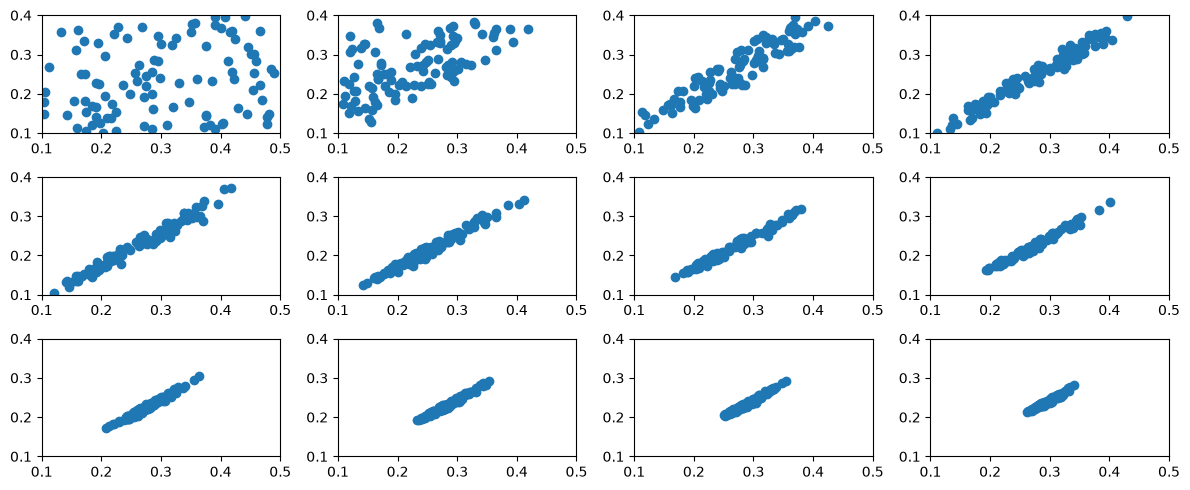

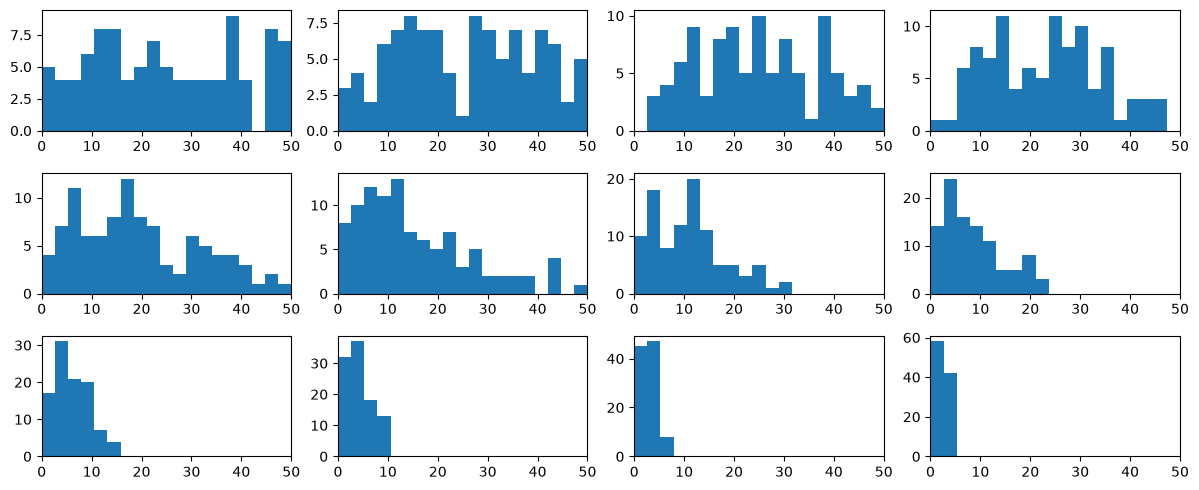

In [30]:
fit = out.generations

fig, axes = plt.subplots(3, 4, figsize=(12,5))
axes = axes.flatten()

for ax, res in zip(axes, fit):
    ax.scatter(res.population.particles[:, 0], res.population.particles[:, 1])
    ax.set_xlim(0.1, 0.5)
    ax.set_ylim(0.1, 0.4)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 4, figsize=(12,5))
axes = axes.flatten()

for ax, res in zip(axes, fit):
    ax.hist(res.population.particles[:, 2], bins=np.linspace(0, 50, 20))
    ax.set_xlim(0, 50)
plt.tight_layout()
plt.show()

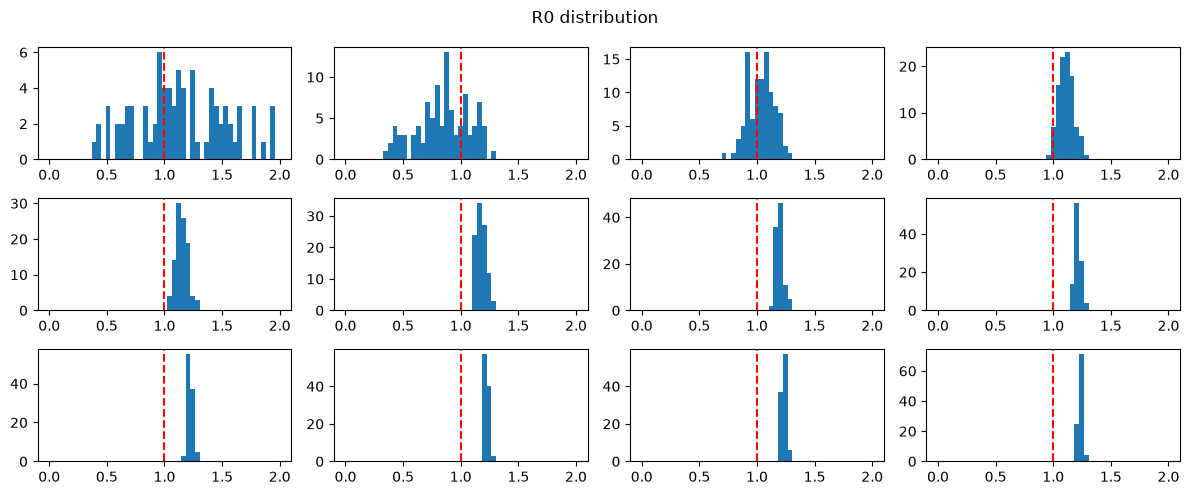

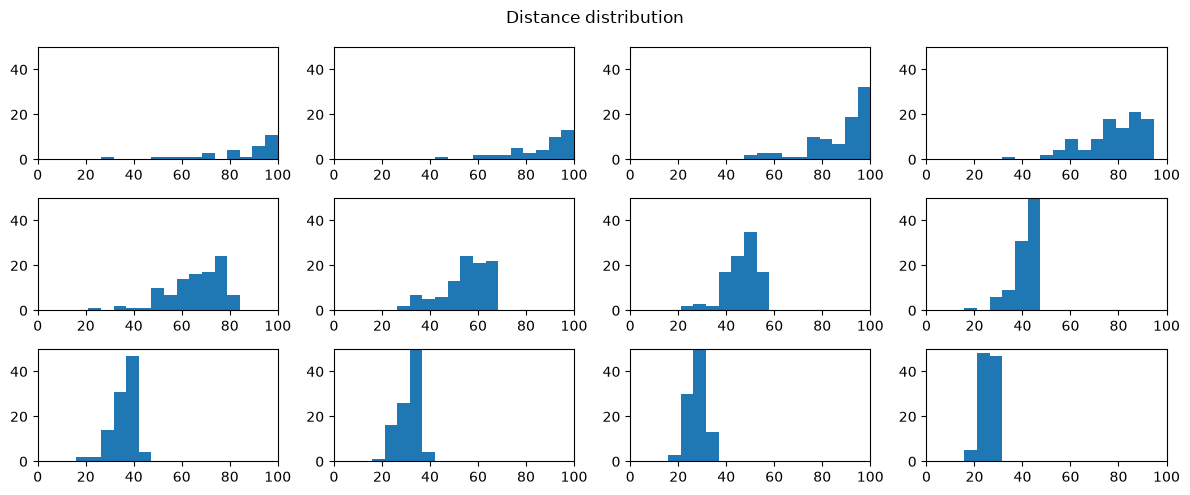

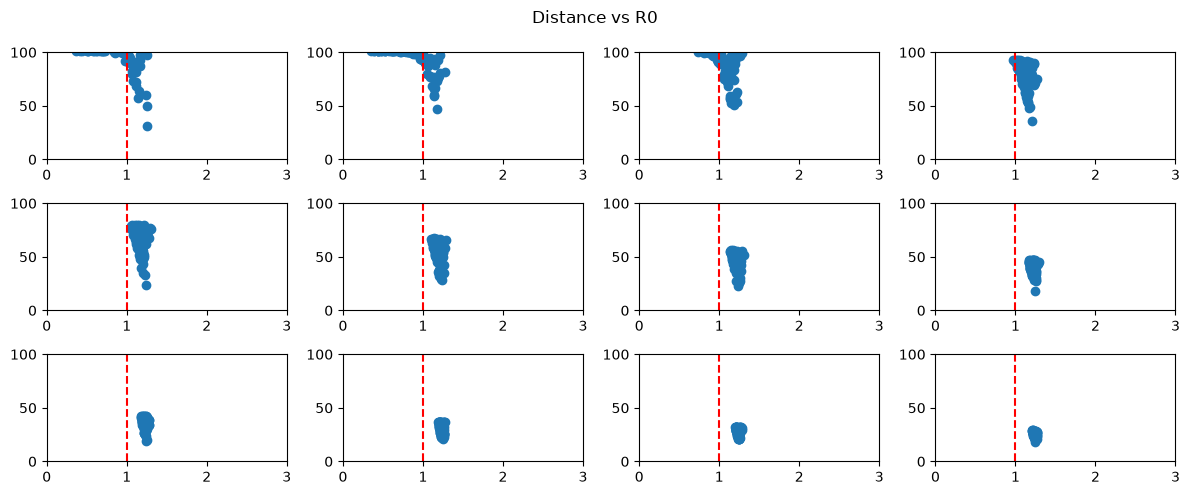

In [31]:
fit = out.generations

fig, axes = plt.subplots(3, 4, figsize=(12,5))
axes = axes.flatten()

for ax, res in zip(axes, fit):
    R0s = res.population.particles[:, 0] / res.population.particles[:, 1]

    ax.hist(R0s, bins = np.linspace(0, 2, 50))
    # ax.set_xlim(0, 2)
    # ax.set_ylim(0, 10)
    ax.axvline(1, linestyle="--", color="red")
plt.suptitle("R0 distribution")
plt.tight_layout()
plt.show()


fig, axes = plt.subplots(3, 4, figsize=(12,5))
axes = axes.flatten()

for ax, res in zip(axes, fit):
    ax.hist(res.population.distances, bins=np.linspace(0, 100, 20))
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 50)
plt.suptitle("Distance distribution")
plt.tight_layout()
plt.show()


fig, axes = plt.subplots(3, 4, figsize=(12,5))
axes = axes.flatten()

for ax, res in zip(axes, fit):
    R0s = res.population.particles[:, 0] / res.population.particles[:, 1]
    distances = res.population.distances
    ax.scatter(R0s, distances)
    ax.set_xlim(0,3)
    ax.set_ylim(0, 100)
    # ax.set_yscale("log")
    ax.axvline(1, linestyle="--", color="red")
plt.suptitle("Distance vs R0")
plt.tight_layout()
plt.show()

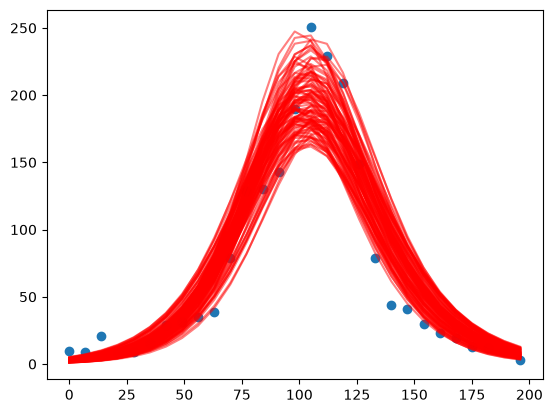

In [32]:
# Plot
for i in range(100):
    params = out.generations[-1].population.particles[i, :]
    vars = estimator._unpack_theta(params)

    mod.initial_states = vars.initial_conditions
    mod.parameters = vars.parameters

    sol = mod.solve_deterministic(t_dat)
    I = sol[0].result.y[:, 1]
    plt.plot(t_dat, I, color="red", alpha=0.5)

plt.scatter(t_dat, I_dat)
plt.show()

## Local covariance

In [33]:
method_spec = ABCMethodSpec(
    n_particles=100,
    quantile=0.5,
    covariance_method="local",
    rng=np.random.default_rng(123)
)

estimator = ABCFit(fitting_problem=problem, method_spec=method_spec)

out = estimator.fit(n_generations=12)

Generation: 0
Tolerance: inf
Accepted: 128 / 128 (100.0%)
Rejected (outside allowed limits): 0 / 128 (0.0%)
Rejected (above distance tolerance): 0 / 128 (0.0%)
ESS: 100.0 / 100
Time taken: 3.83 seconds


Generation: 1
Tolerance: 101.04
Accepted: 119 / 367 (32.4%)
Rejected (outside allowed limits): 207 / 367 (56.4%)
Rejected (above distance tolerance): 41 / 160 (25.6%)
ESS: 90.9 / 100
Time taken: 6.65 seconds


Generation: 2
Tolerance: 99.44
Accepted: 122 / 356 (34.3%)
Rejected (outside allowed limits): 164 / 356 (46.1%)
Rejected (above distance tolerance): 70 / 192 (36.5%)
ESS: 89.9 / 100
Time taken: 8.57 seconds


Generation: 3
Tolerance: 89.64
Accepted: 106 / 278 (38.1%)
Rejected (outside allowed limits): 86 / 278 (30.9%)
Rejected (above distance tolerance): 86 / 192 (44.8%)
ESS: 85.2 / 100
Time taken: 8.15 seconds


Generation: 4
Tolerance: 74.94
Accepted: 130 / 333 (39.0%)
Rejected (outside allowed limits): 109 / 333 (32.7%)
Rejected (above distance tolerance): 94 / 224 (42.0%)
ESS

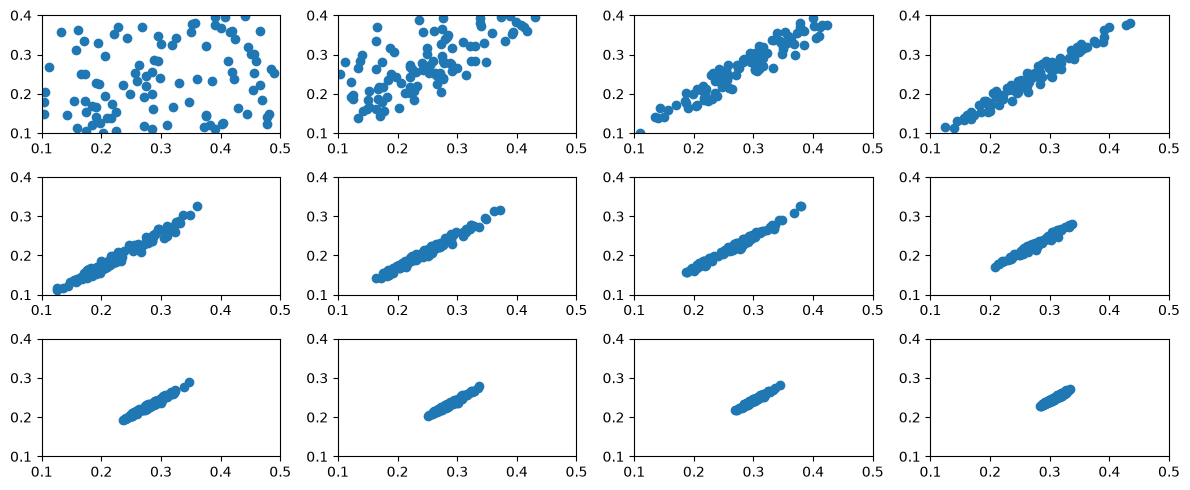

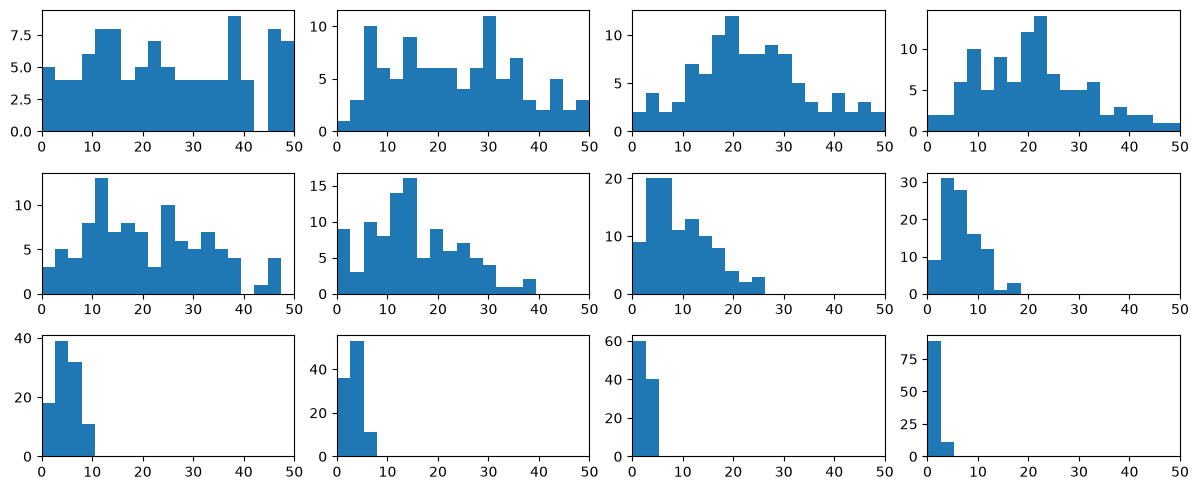

In [34]:
fit = out.generations

fig, axes = plt.subplots(3, 4, figsize=(12,5))
axes = axes.flatten()

for ax, res in zip(axes, fit):
    ax.scatter(res.population.particles[:, 0], res.population.particles[:, 1])
    ax.set_xlim(0.1, 0.5)
    ax.set_ylim(0.1, 0.4)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 4, figsize=(12,5))
axes = axes.flatten()

for ax, res in zip(axes, fit):
    ax.hist(res.population.particles[:, 2], bins=np.linspace(0, 50, 20))
    ax.set_xlim(0, 50)
plt.tight_layout()
plt.show()

## Nearest neighbour covariance

### Mahalanobis distance

In [35]:
method_spec = ABCMethodSpec(
    n_particles=100,
    quantile=0.5,
    covariance_method="knn",
    distance_method="mahalanobis",
    k=20,
    rng=np.random.default_rng(123)
)

estimator = ABCFit(fitting_problem=problem, method_spec=method_spec)

out = estimator.fit(n_generations=12)

Generation: 0
Tolerance: inf
Accepted: 128 / 128 (100.0%)
Rejected (outside allowed limits): 0 / 128 (0.0%)
Rejected (above distance tolerance): 0 / 128 (0.0%)
ESS: 100.0 / 100
Time taken: 1.84 seconds


Generation: 1
Tolerance: 101.04
Accepted: 117 / 434 (27.0%)
Rejected (outside allowed limits): 178 / 434 (41.0%)
Rejected (above distance tolerance): 139 / 256 (54.3%)
ESS: 85.3 / 100
Time taken: 6.37 seconds


Generation: 2
Tolerance: 100.12
Accepted: 107 / 431 (24.8%)
Rejected (outside allowed limits): 111 / 431 (25.8%)
Rejected (above distance tolerance): 213 / 320 (66.6%)
ESS: 67.9 / 100
Time taken: 5.66 seconds


Generation: 3
Tolerance: 92.62
Accepted: 130 / 329 (39.5%)
Rejected (outside allowed limits): 105 / 329 (31.9%)
Rejected (above distance tolerance): 94 / 224 (42.0%)
ESS: 72.1 / 100
Time taken: 6.95 seconds


Generation: 4
Tolerance: 80.22
Accepted: 120 / 322 (37.3%)
Rejected (outside allowed limits): 66 / 322 (20.5%)
Rejected (above distance tolerance): 136 / 256 (53.1%)

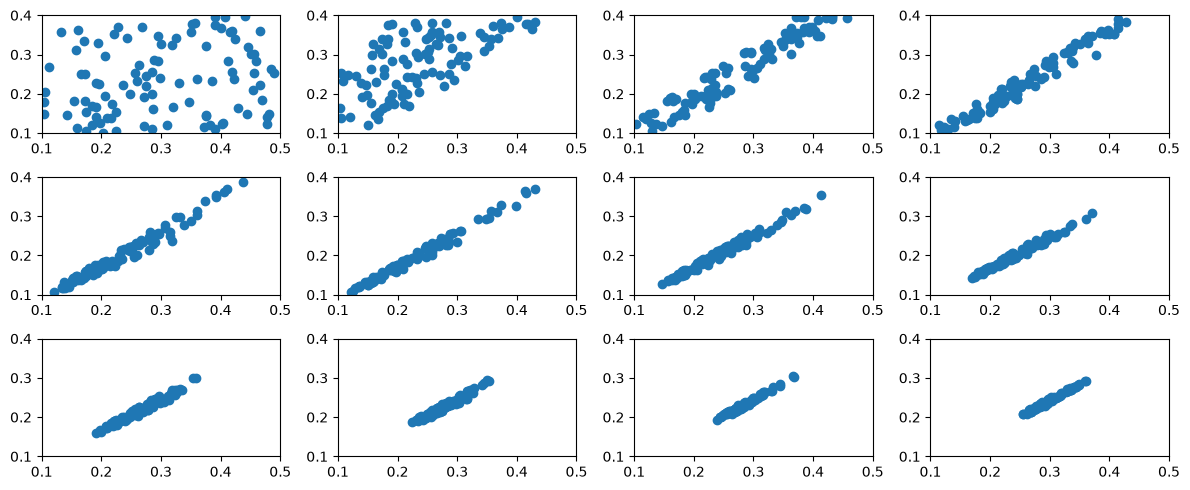

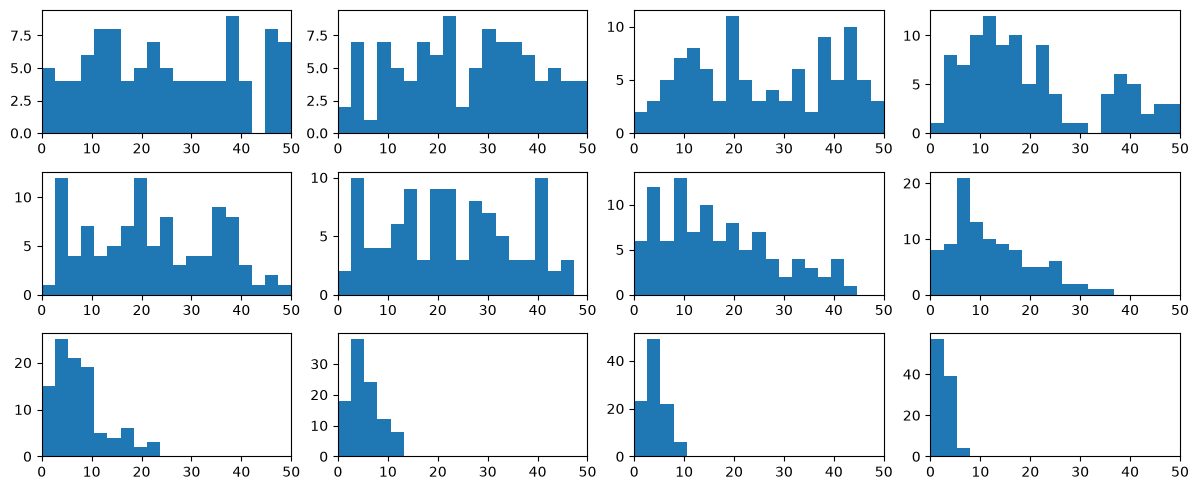

In [36]:
fit = out.generations

fig, axes = plt.subplots(3, 4, figsize=(12,5))
axes = axes.flatten()

for ax, res in zip(axes, fit):
    ax.scatter(res.population.particles[:, 0], res.population.particles[:, 1])
    ax.set_xlim(0.1, 0.5)
    ax.set_ylim(0.1, 0.4)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 4, figsize=(12,5))
axes = axes.flatten()

for ax, res in zip(axes, fit):
    ax.hist(res.population.particles[:, 2], bins=np.linspace(0, 50, 20))
    ax.set_xlim(0, 50)
plt.tight_layout()
plt.show()

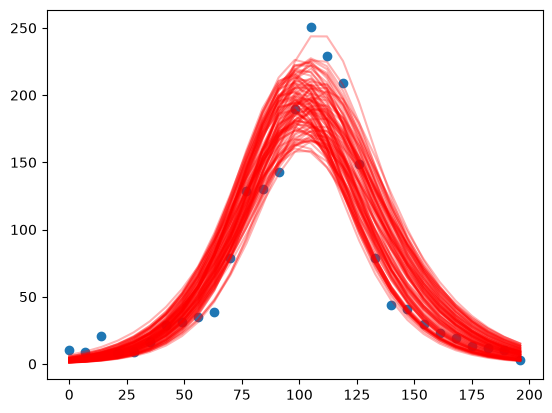

In [39]:
# Plot
for i in range(100):
    params = out.generations[-1].population.particles[i, :]
    vars = estimator._unpack_theta(params)

    mod.initial_states = vars.initial_conditions
    mod.parameters = vars.parameters

    sol = mod.solve_deterministic(t_dat)
    I = sol[0].result.y[:, 1]
    plt.plot(t_dat, I, color="red", alpha=0.3)

plt.scatter(t_dat, I_dat)
plt.show()